<a href="https://colab.research.google.com/github/Alphaoumarsow4/Alpha-s-/blob/main/Sow_Alpha_Capstone7_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
%pip install pandas numpy scikit-learn matplotlib seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score
)

RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
# Step 4: Load a public phishing-email dataset

dataset_url = "https://raw.githubusercontent.com/rokibulroni/Phishing-Email-Dataset/main/Ling.csv"

df = pd.read_csv(dataset_url)

print("Dataset loaded successfully!")
print("Total emails:", len(df))
print("Column names:", df.columns.tolist())

# Display the first five emails
display(df.head())

Dataset loaded successfully!
Total emails: 2859
Column names: ['subject', 'body', 'label']


,subject,body,label
0,job posting - apple-iss research center,content - length : 3386 apple-iss research cen...,0
1,NaN,"lang classification grimes , joseph e . and ba...",0
2,query : letter frequencies for text identifica...,i am posting this inquiry for sergei atamas ( ...,0
3,risk,a colleague and i are researching the differin...,0
4,request book information,earlier this morning i was on the phone with a...,0


In [ ]:
# Clean the email data

df = df[['subject', 'body', 'label']].copy()

df['subject'] = df['subject'].fillna('')
df['body'] = df['body'].fillna('')

# Put the subject and message together
df['email_text'] = (
    df['subject'].astype(str) + ' ' +
    df['body'].astype(str)
).str.strip()

df = df[df['email_text'] != '']
df = df.drop_duplicates(subset=['email_text'])

# Make sure the labels are numbers
df['label'] = pd.to_numeric(df['label'], errors='coerce')
df = df.dropna(subset=['label'])
df['label'] = df['label'].astype(int)

print("Total emails:", len(df))
print(df['label'].value_counts())

df.head()

Total emails: 2859
label
0    2401
1     458
Name: count, dtype: int64


,subject,body,label,email_text
0,job posting - apple-iss research center,content - length : 3386 apple-iss research cen...,0,job posting - apple-iss research center conten...
1,,"lang classification grimes , joseph e . and ba...",0,"lang classification grimes , joseph e . and ba..."
2,query : letter frequencies for text identifica...,i am posting this inquiry for sergei atamas ( ...,0,query : letter frequencies for text identifica...
3,risk,a colleague and i are researching the differin...,0,risk a colleague and i are researching the dif...
4,request book information,earlier this morning i was on the phone with a...,0,request book information earlier this morning ...


In [ ]:

# Split the data for training and testing

X = df['email_text']
y = df['label']

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42,
    stratify=y_temp
)

print("Training emails:", len(X_train))
print("Validation emails:", len(X_val))
print("Testing emails:", len(X_test))


Training emails: 2001
Validation emails: 429
Testing emails: 429


In [ ]:

# Train the first email detection model

from sklearn.pipeline import Pipeline

model = Pipeline([
    ('tfidf', TfidfVectorizer(
        stop_words='english',
        max_features=5000
    )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        random_state=42,
        class_weight='balanced'
    ))
])

model.fit(X_train, y_train)

# Check performance on the validation data
y_pred = model.predict(X_val)
y_prob = model.predict_proba(X_val)[:, 1]

print("Validation Results")
print("Accuracy:", round(accuracy_score(y_val, y_pred), 4))
print("Precision:", round(precision_score(y_val, y_pred), 4))
print("Recall:", round(recall_score(y_val, y_pred), 4))
print("F1 Score:", round(f1_score(y_val, y_pred), 4))
print("AUC:", round(roc_auc_score(y_val, y_prob), 4))


Validation Results
Accuracy: 0.9977
Precision: 0.9857
Recall: 1.0
F1 Score: 0.9928
AUC: 1.0


In [ ]:

# Tune the model with cross-validation

from sklearn.model_selection import GridSearchCV

parameters = {
    'tfidf__ngram_range': [(1, 1), (1, 2)],
    'classifier__C': [0.1, 1, 10],
    'classifier__class_weight': ['balanced', None]
}

grid = GridSearchCV(
    model,
    parameters,
    cv=3,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Cross-validation F1:", round(grid.best_score_, 4))

best_model = grid.best_estimator_

predictions = best_model.predict(X_val)

print("\nUpdated validation results:")
print("Accuracy:", round(accuracy_score(y_val, predictions), 4))
print("Precision:", round(precision_score(y_val, predictions), 4))
print("Recall:", round(recall_score(y_val, predictions), 4))
print("F1 Score:", round(f1_score(y_val, predictions), 4))


Best parameters: {'classifier__C': 1, 'classifier__class_weight': 'balanced', 'tfidf__ngram_range': (1, 2)}
Cross-validation F1: 0.9841

Updated validation results:
Accuracy: 0.9953
Precision: 0.9718
Recall: 1.0
F1 Score: 0.9857


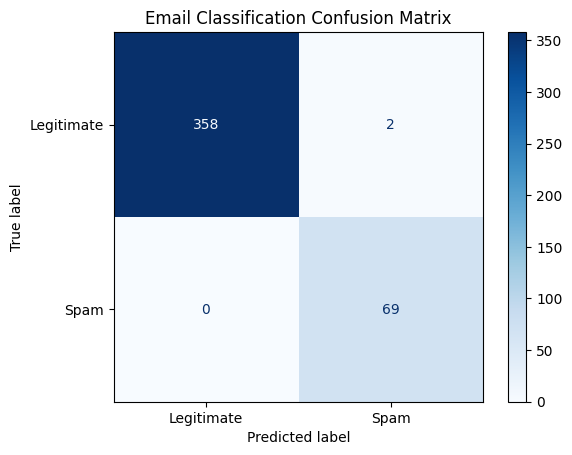

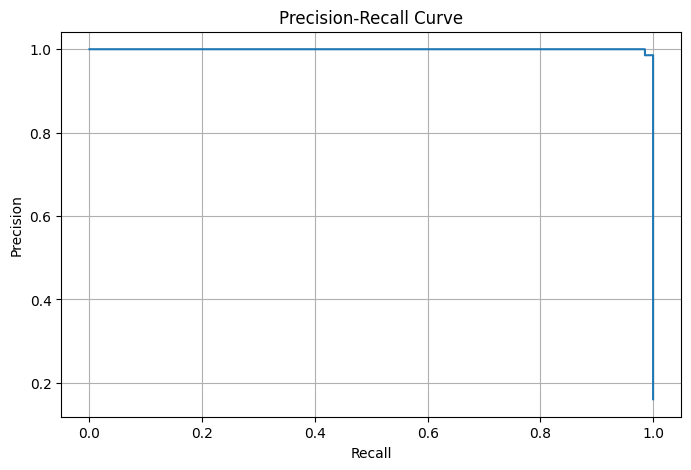

In [ ]:

# Check the model's predictions

from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve

ConfusionMatrixDisplay.from_estimator(
    best_model,
    X_val,
    y_val,
    display_labels=['Legitimate', 'Spam'],
    cmap='Blues'
)

plt.title('Email Classification Confusion Matrix')
plt.show()

# Plot precision and recall

probabilities = best_model.predict_proba(X_val)[:, 1]

precision, recall, thresholds = precision_recall_curve(
    y_val, probabilities
)

plt.figure(figsize=(8, 5))
plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(True)
plt.show()


,Threshold,Precision,Recall,F1 Score,False Positives,False Negatives
0,0.3,0.8846,1.0000,0.9388,9,0
1,0.5,0.9718,1.0000,0.9857,2,0
2,0.7,1.0000,0.9130,0.9545,0,6
3,0.9,1.0000,0.5217,0.6857,0,33


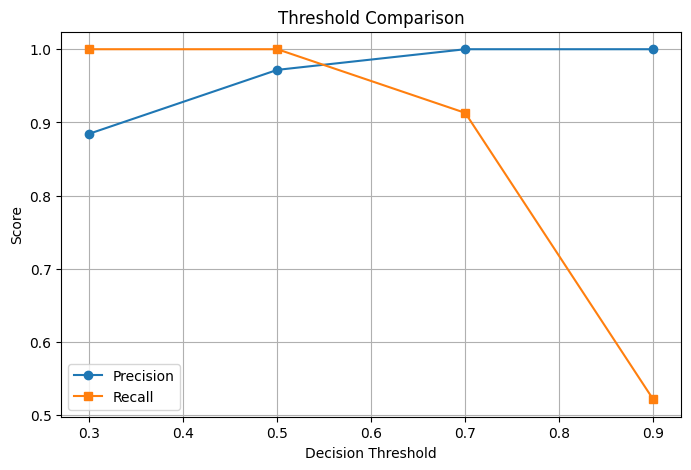

In [ ]:

# Compare different decision thresholds

from sklearn.metrics import confusion_matrix

probabilities = best_model.predict_proba(X_val)[:, 1]

results = []

for threshold in [0.3, 0.5, 0.7, 0.9]:
    predicted = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, predicted, labels=[0, 1]
    ).ravel()

    results.append({
        'Threshold': threshold,
        'Precision': round(precision_score(y_val, predicted, zero_division=0), 4),
        'Recall': round(recall_score(y_val, predicted, zero_division=0), 4),
        'F1 Score': round(f1_score(y_val, predicted, zero_division=0), 4),
        'False Positives': fp,
        'False Negatives': fn
    })

threshold_df = pd.DataFrame(results)

display(threshold_df)

plt.figure(figsize=(8, 5))
plt.plot(threshold_df['Threshold'], threshold_df['Precision'],
         marker='o', label='Precision')
plt.plot(threshold_df['Threshold'], threshold_df['Recall'],
         marker='s', label='Recall')

plt.xlabel('Decision Threshold')
plt.ylabel('Score')
plt.title('Threshold Comparison')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# Test how the model handles disguised text

import re

def disguise_email(text):
    words = re.findall(r'\b\w{6,}\b', text)

    for word in set(words):
        disguised = '\u200b'.join(word)
        text = re.sub(
            r'\b' + re.escape(word) + r'\b',
            lambda match: disguised,
            text,
            flags=re.IGNORECASE
        )

    return text

spam_emails = X_val[y_val == 1]
disguised_emails = spam_emails.apply(disguise_email)

original_predictions = best_model.predict(spam_emails)
disguised_predictions = best_model.predict(disguised_emails)

original_detection = original_predictions.mean()
disguised_detection = disguised_predictions.mean()

print("Original spam detection:",
      round(original_detection * 100, 2), "%")

print("After text obfuscation:",
      round(disguised_detection * 100, 2), "%")

print("Emails tested:", len(spam_emails))
print("Emails changed:",
      (spam_emails != disguised_emails).sum())


Original spam detection: 100.0 %
After text obfuscation: 100.0 %
Emails tested: 69
Emails changed: 69


In [ ]:

# Train a second model using original and modified emails

from sklearn.pipeline import Pipeline

modified_train = X_train.apply(disguise_email)

X_augmented = pd.concat([X_train, modified_train])
y_augmented = pd.concat([y_train, y_train])

char_model = Pipeline([
    ('tfidf', TfidfVectorizer(
        analyzer='char',
        ngram_range=(3, 5),
        max_features=10000
    )),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

char_model.fit(X_augmented, y_augmented)

# Combine predictions from both models
def ensemble_probability(texts):
    word_scores = best_model.predict_proba(texts)[:, 1]
    char_scores = char_model.predict_proba(texts)[:, 1]
    return (word_scores + char_scores) / 2

original_scores = ensemble_probability(spam_emails)
modified_scores = ensemble_probability(disguised_emails)

print("Ensemble results")
print("Original detection:",
      round((original_scores >= 0.5).mean() * 100, 2), "%")
print("Modified detection:",
      round((modified_scores >= 0.5).mean() * 100, 2), "%")

print("Original average probability:",
      round(original_scores.mean(), 4))
print("Modified average probability:",
      round(modified_scores.mean(), 4))


Ensemble results
Original detection: 100.0 %
Modified detection: 98.55 %
Original average probability: 0.8804
Modified average probability: 0.8473


In [ ]:

# Final evaluation using the test emails

test_scores = ensemble_probability(X_test)
test_predictions = (test_scores >= 0.5).astype(int)

print("Final Test Results")
print("Accuracy:", round(accuracy_score(y_test, test_predictions), 4))
print("Precision:", round(precision_score(y_test, test_predictions), 4))
print("Recall:", round(recall_score(y_test, test_predictions), 4))
print("F1 Score:", round(f1_score(y_test, test_predictions), 4))
print("AUC:", round(roc_auc_score(y_test, test_scores), 4))

print("\nClassification Report:")
print(classification_report(
    y_test, test_predictions,
    target_names=['Legitimate', 'Spam']
))


# Function for checking new emails

def phishing_probability(email_text):
    if not isinstance(email_text, str):
        raise TypeError("Email must be a string.")

    if not email_text.strip():
        raise ValueError("Email cannot be empty.")

    score = ensemble_probability([email_text])[0]
    return round(float(score), 4)


# Try the function with two examples

example1 = "Hello, the meeting has moved to Monday at 10 AM."

example2 = (
    "Urgent! Your account has been suspended. "
    "Verify your password immediately to restore access."
)

print("\nPrediction Examples")
print("Example 1:", phishing_probability(example1))
print("Example 2:", phishing_probability(example2))


Final Test Results
Accuracy: 0.9907
Precision: 0.9444
Recall: 1.0
F1 Score: 0.9714
AUC: 1.0

Classification Report:
              precision    recall  f1-score   support

  Legitimate       1.00      0.99      0.99       361
        Spam       0.94      1.00      0.97        68

    accuracy                           0.99       429
   macro avg       0.97      0.99      0.98       429
weighted avg       0.99      0.99      0.99       429


Prediction Examples
Example 1: 0.4495
Example 2: 0.6425


### Conclusion

In this project, I developed an email classification system using TF-IDF, logistic regression, and an ensemble model. I cleaned 2,859 emails and divided them into training, validation, and testing sets.

The final ensemble model achieved 99.07% accuracy, 94.44% precision, 100% recall, and a 97.14% F1 score on the test data. I also tested different decision thresholds and found that reducing false positives could increase the number of suspicious messages missed.

I tested text obfuscation as an adversarial technique and trained a second model using character-level features and modified emails. The ensemble detected 98.55% of the modified spam emails, compared with 100% for the original model. This showed that adding a defense does not automatically improve performance.

One important limitation is that the Ling dataset contains spam labels rather than verified phishing labels. Therefore, these results demonstrate spam classification performance and should not be interpreted as proven real-world phishing detection accuracy. Additional evaluation on verified phishing emails would be necessary before deploying this system.

In [ ]:

# Save the data and software requirements

from importlib.metadata import version
from google.colab import files

packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "matplotlib",
    "seaborn"
]

with open("requirements.txt", "w") as f:
    for package in packages:
        f.write(f"{package}=={version(package)}\n")

df.to_csv("cleaned_email_dataset.csv", index=False)

print("Files created successfully!")
print(open("requirements.txt").read())

files.download("requirements.txt")
files.download("cleaned_email_dataset.csv")


Files created successfully!
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
matplotlib==3.10.0
seaborn==0.13.2



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>